# P281 Homework Set 1
2026-10-06 hw1_10_6.ipynb Bella K

In [ ]:
import numpy as np
from numpy import pi, sqrt, cos, sin, exp
import matplotlib.pyplot as plt
import pandas as pd
import scipy

## Question 1
Print all Catalan numbers less than 10^9

In [ ]:
c_n = 1
n = 0

while c_n <= 1e9:
    print(f'c_n: {c_n:,}, n: {n}')
    n = n + 1
    c_n = (4 * n + 2)/(n + 2) * c_n

c_n: 1, n: 0
c_n: 2.0, n: 1
c_n: 5.0, n: 2
c_n: 14.0, n: 3
c_n: 42.0, n: 4
c_n: 132.0, n: 5
c_n: 429.0, n: 6
c_n: 1,430.0, n: 7
c_n: 4,862.0, n: 8
c_n: 16,796.0, n: 9
c_n: 58,786.0, n: 10
c_n: 208,012.0, n: 11
c_n: 742,900.0, n: 12
c_n: 2,674,440.0, n: 13
c_n: 9,694,845.0, n: 14
c_n: 35,357,670.0, n: 15
c_n: 129,644,790.0, n: 16
c_n: 477,638,700.0, n: 17


## Question 2
Curve plotting

#### 2(a) Plotting the deltoid curve

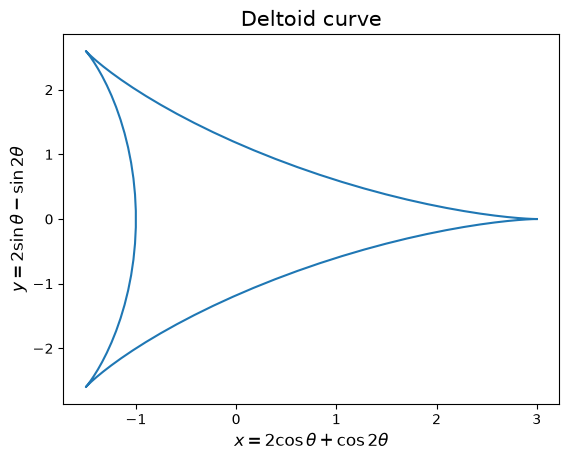

In [ ]:
theta = np.linspace(0, 2 * pi, 100)
x = 2 * cos(theta) + cos(2 * theta)
y = 2 * sin(theta) - sin(2 * theta)

plt.plot(x, y)
plt.title('Deltoid curve', size = 15)
plt.xlabel('$x = 2\\cos{\\theta} + \\cos{2\\theta}$', size = 12)
plt.ylabel('$y = 2\\sin{\\theta} - \\sin{2\\theta}$', size = 12)
plt.show()

#### 2(b) Plotting the Galilean spiral using polar coords

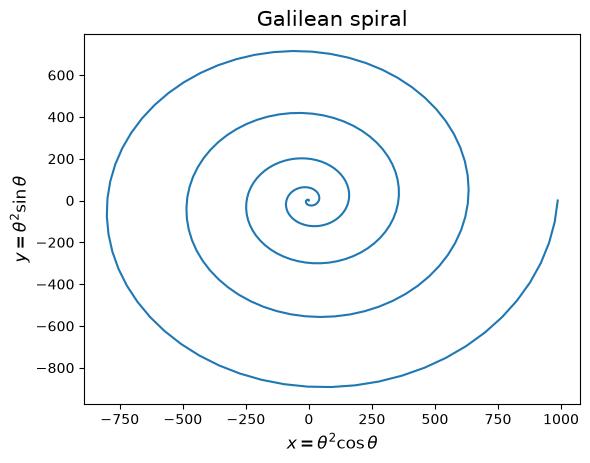

In [ ]:
theta = np.linspace(0, 10 * pi, 300)
r = theta**2
x = r * cos(theta)
y = r * sin(theta)

plt.plot(x, y)
plt.title('Galilean spiral', size = 15)
plt.xlabel('$x = \\theta^2\\cos{\\theta}$', size = 12)
plt.ylabel('$y = \\theta^2\\sin{\\theta}$', size = 12)
plt.show()

#### 2(c) Plotting Fey's function

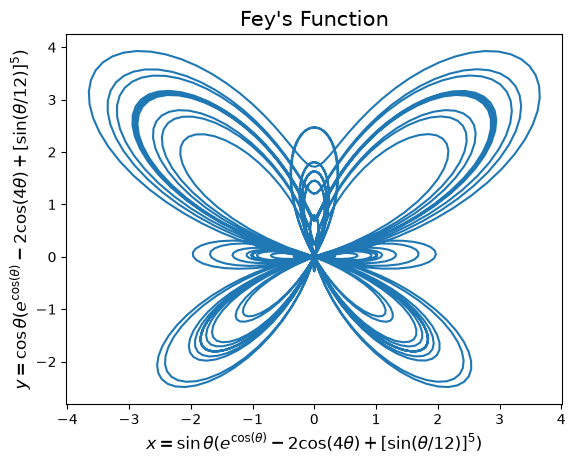

In [ ]:
theta = np.linspace(0, 24 * pi, 2000)
r = exp(cos(theta)) - 2 * cos(4 * theta) + (sin(theta / 12))**5

# Note here that I changed x to y and y to x in order to make the butterfly upright!
x = r * sin(theta)
y = r * cos(theta)

plt.plot(x, y)
plt.title('Fey\'s Function', size = 15)
plt.xlabel('$x = \\sin{\\theta}(e^{\\cos(\\theta)} - 2\\cos(4\\theta) + [\\sin(\\theta / 12)]^5)$', size = 12)
plt.ylabel('$y = \\cos{\\theta}(e^{\\cos(\\theta)} - 2\\cos(4\\theta) + [\\sin(\\theta / 12)]^5)$', size = 12)
plt.show()

## Question 3
Plotting STM data

Text(0, 0.5, 'Vertical Distance')

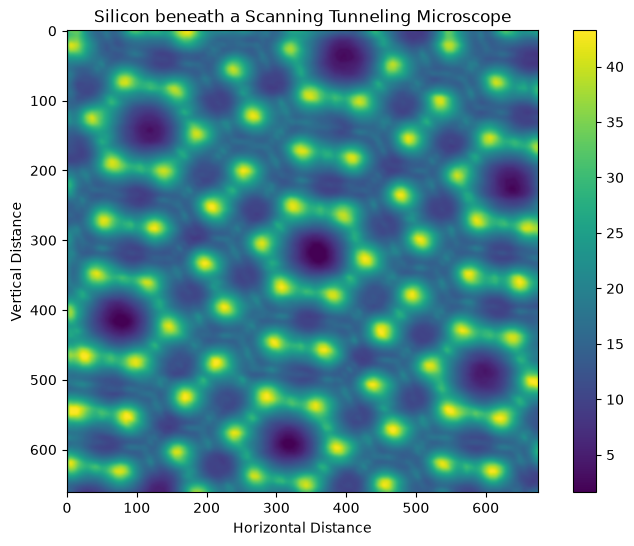

In [ ]:
df_stm = pd.read_csv('./stm.txt', sep=' ')
plt.figure(figsize=(9,6))
plt.imshow(df_stm)
plt.colorbar()
plt.title('Silicon beneath a Scanning Tunneling Microscope')
plt.xlabel('Horizontal Distance')
plt.ylabel('Vertical Distance')

## Question 4
Quantum Harmonic Oscillator: Plotting p(x) (probability particle is at x) for different energies

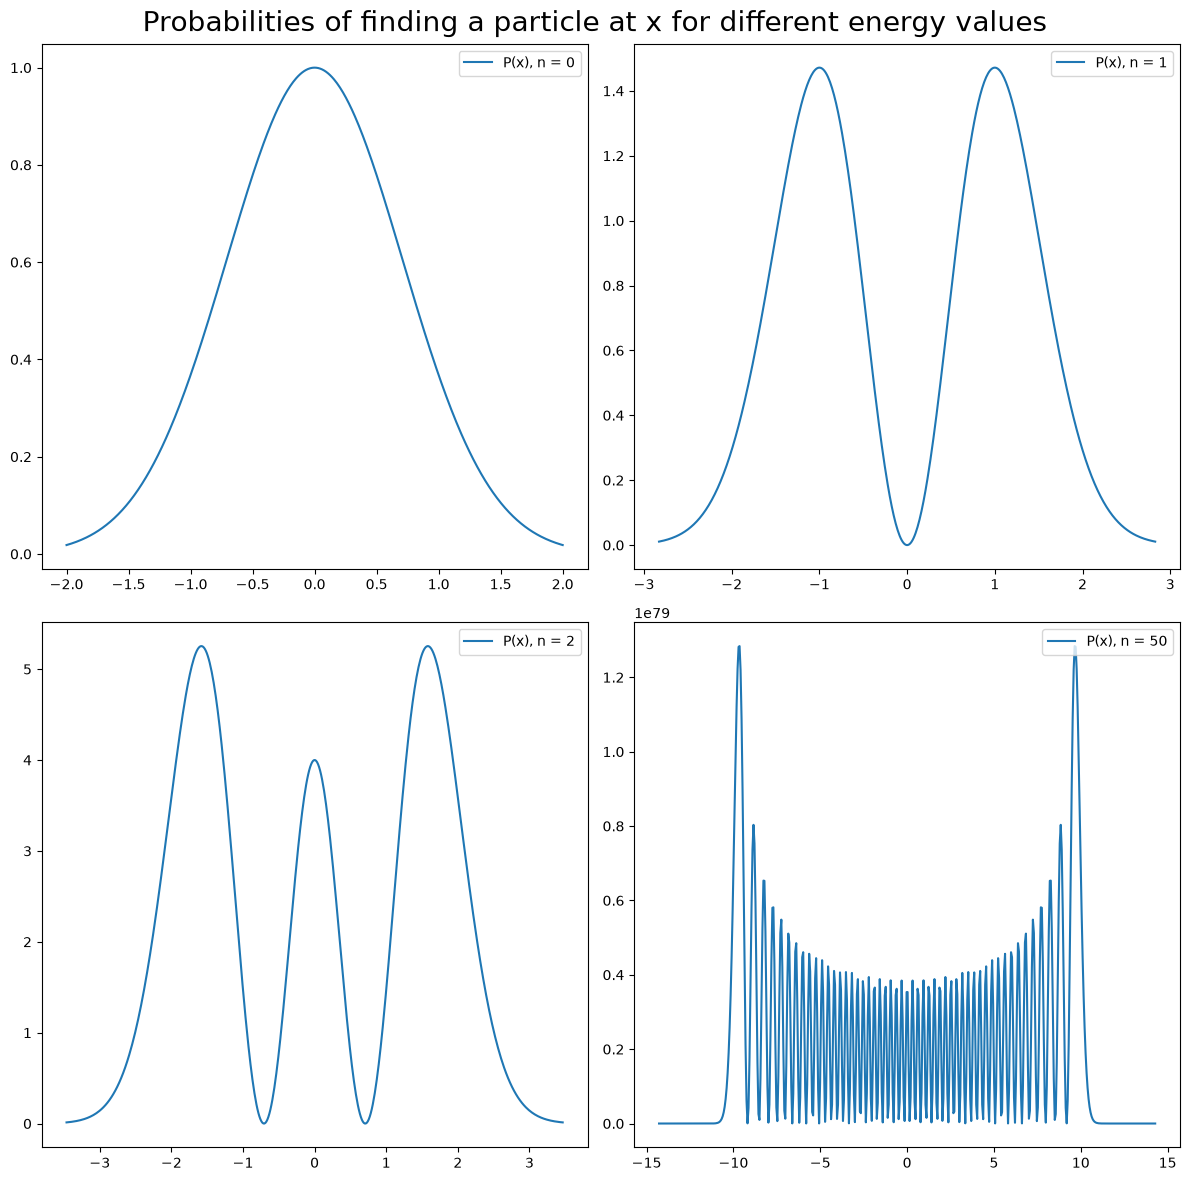

In [ ]:
hermite = scipy.special.eval_hermite
n_list = [0, 1, 2, 50]
i = 1
plt.figure(figsize = (12, 12))

for n in n_list:
    plt.subplot(220 + i)

    x_max = 2 * sqrt(n + 1)
    x = np.linspace(-x_max, x_max, 500)
    p = exp(-x**2) * (hermite(n, x))**2

    plt.plot(x, p, label = f'P(x), n = {n}')
    plt.legend(loc = 'upper right')
    i = i + 1

plt.suptitle('Probabilities of finding a particle at x for different energy values', size = 20)
plt.tight_layout()
plt.show()

## Question 5
Catalan mountain ranges

In [ ]:
# Modified catalan.py 1/30/18 D. Candela on 10/1/2026 by B. Kalina
n = int(input('n? '))
valid_lst = []

for b in range(2**(2*n)):
    lst = [b >> shft & 1 for shft in range(2*n)]

    # appends the new list no matter what
    valid_lst.append(lst)

    # deletes the list if there isn't the right number of 'ups'
    if sum(lst) != n:
        del valid_lst[-1]
    else:
        # checks to see if the mountain ever dips below the starting level
        a = 0
        i = 0
        while a >= 0 and i < 2 * n:
            if lst[i] == 1:
                a = a + 1
            else:
                a = a - 1
            # print(f'lst = {lst}, a = {a}, i = {i}')
            i = i + 1
        if a < 0:
            del valid_lst[-1]
            # print('del')
            
print(f'Mountain ranges (n = {n}): ', valid_lst)
print(f'Catalan number (n = {n}): ', len(valid_lst))

Mountain ranges (n = 3):  [[1, 1, 1, 0, 0, 0], [1, 1, 0, 1, 0, 0], [1, 0, 1, 1, 0, 0], [1, 1, 0, 0, 1, 0], [1, 0, 1, 0, 1, 0]]
Catalan number (n = 3):  5


## Question 6
Printing out the Catalan Mountain Ranges

In [ ]:
def valid_ranges(n):
    '''Returns the valid Catalan mountain ranges as a list of binary lists when given n'''
    valid_lst = []

    for b in range(2**(2*n)):
        lst = [b >> shft & 1 for shft in range(2*n)]

        # appends the new list no matter what
        valid_lst.append(lst)

        # deletes the list if there isn't the right number of 'ups'
        if sum(lst) != n:
            del valid_lst[-1]
        else:
            # checks to see if the mountain ever dips below the starting level
            a = 0
            i = 0
            while a >= 0 and i < 2 * n:
                if lst[i] == 1:
                    a = a + 1
                else:
                    a = a - 1
                # print(f'lst = {lst}, a = {a}, i = {i}')
                i = i + 1
            if a < 0:
                del valid_lst[-1]
                # print('del')
    return valid_lst

In [ ]:
n = int(input('n? '))

ranges = valid_ranges(n)

l = []
for j in ranges: 
    # initializes a 2d array of the max possible height 
    # and the length for a mountain range with # of up/downstrokes n
    range_array = np.empty((n, 2 * n), dtype = str)

    # indices for which row/column to place the up/downstroke into
    row = 0
    col = 0
    last = 1

    # index over the length of the range and place the up/downstroke
    # into the correct row in range_array depending on the last character
    for i in j:
        if i:
            range_array[row, col] = '/'
        else:
            range_array[row, col] = '\\'
        col = col + 1
        if last == i and i:
            row = row + 1
        elif last == i and i == 0:
            row = row - 1
        last = i
    l.append(range_array)
    print('range_array', range_array)

# catalan_pic = np.array2string(range_array)
# print('l', l)
# print('catalan_pic', catalan_pic)

IndexError: index 2 is out of bounds for axis 0 with size 2

For question 6, I first made Q5 into a function that returns the valid Catalan mountain ranges as a list of lists.

I thought the best way to approach this problem would be to have a 2d array of up/downstrokes, then convert the array into a string with n lines.

I ran into an issue with indexing rows in the 2d array and could not resolve it.